# LE3 - Network Modeling & Filtering

This notebook documents the construction and filtering of various network types for football match analysis:

1. **Pass Networks** (Player-to-Player): Directed networks of passing interactions
2. **Match Networks** (Team-to-Team): Directed networks of match outcomes
3. **Player-Team Networks** (Bipartite): Two-mode networks showing player-team relationships
4. **Network Projection**: Converting two-mode networks to one-mode

We will also explore various filtering and reduction techniques.

In [1]:
# Import required libraries
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from networkx.algorithms import bipartite


# Add project root to path (So we can run the notebook from any location)
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

In [2]:
from src.common import load_json_fixed
from src.config import (
    PASS_NETWORKS_DIR,
    MATCH_NETWORKS_DIR,
    PLAYER_TEAM_NETWORKS_DIR,
    PLAYERS_FILE,
    TEAMS_FILE,
)

c:\Users\FHNW\AppData\Local\pypoetry\Cache\virtualenvs\san-ZcAQNQuH-py3.13\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Setup
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

In [4]:
# Load base data
df_players = pd.DataFrame(load_json_fixed(PLAYERS_FILE))
df_teams = pd.DataFrame(load_json_fixed(TEAMS_FILE))

print(f"Players loaded: {len(df_players)}")
print(f"Teams loaded: {len(df_teams)}")

Players loaded: 3603
Teams loaded: 142


## 1. Pass Networks (Player-to-Player)

**Network Type**: Directed, Weighted

**Nodes**: Individual football players

**Edges**: Directed edges from passer to receiver

**Edge Attributes**:
- `weight` / `pass_count`: Number of successful passes
- `accuracy`: Proportion of successful passes
- `avg_pass_distance`: Average Euclidean distance of passes
- `avg_pass_angle`: Average angle of passes

**Construction Method**: 
We identify pass receivers using a spatio-temporal heuristic: the next event by a teammate within a distance threshold (5m) and time threshold (5s) of the pass endpoint.

In [5]:
# Load a generated pass network (using pre-generated networks)
pass_network_path = PASS_NETWORKS_DIR / 'pass_network_Germany.gexf'
G_pass = nx.read_gexf(pass_network_path)

print("=== Pass Network Properties ===")
print(f"Network Type: {type(G_pass)}")
print(f"Directed: {G_pass.is_directed()}")
print(f"Number of Nodes (|V|): {G_pass.number_of_nodes()}")
print(f"Number of Edges (|E|): {G_pass.number_of_edges()}")
print(f"Density: {nx.density(G_pass):.6f}")

# Check for weakly connected components
if G_pass.is_directed():
    num_components = nx.number_weakly_connected_components(G_pass)
    components = list(nx.weakly_connected_components(G_pass))
    largest_component = max(components, key=len)
    print(f"Weakly Connected Components: {num_components}")
    print(f"Largest Component Size: {len(largest_component)} nodes")
    
# Sample node attributes
sample_node = list(G_pass.nodes())[0]
print(f"\nSample Node Attributes (Node {sample_node}):")
for key, value in G_pass.nodes[sample_node].items():
    print(f"  {key}: {value}")

# Sample edge attributes
sample_edge = list(G_pass.edges())[0]
print(f"\nSample Edge Attributes (Edge {sample_edge}):")
for key, value in G_pass.edges[sample_edge].items():
    print(f"  {key}: {value}")

=== Pass Network Properties ===
Network Type: <class 'networkx.classes.digraph.DiGraph'>
Directed: True
Number of Nodes (|V|): 473
Number of Edges (|E|): 8786
Density: 0.039354
Weakly Connected Components: 8
Largest Component Size: 283 nodes

Sample Node Attributes (Node 51217):
  passport_area: Sweden
  weight_kg: 75
  birth_date: 1994-04-21
  height_cm: 181
  position_role: Defender
  preferred_foot: left
  player_name: L. Augustinsson
  national_team_id: 7047
  current_team_name: Werder Bremen
  currentTeamId: 2443
  degree_centrality: 0.09110169491525423
  degree: 43
  betweenness_centrality: 0.0017507676898533017
  closeness_centrality: 0.08949539828625833
  pagerank: 0.004069617117043447
  kcore_number: 15
  modularity_class_louvain: 12
  modularity_class_label_propagation: 0
  modularity_class_greedy: 12
  modularity_class_girvan_newman: 0
  label: L. Augustinsson

Sample Edge Attributes (Edge ('51217', '77')):
  pass_count: 121
  accuracy: 1.0
  avg_pass_distance: 22.3371340765

## 2. Match Networks (Team-to-Team)

**Network Type**: Directed, Weighted

**Nodes**: Football teams

**Edges**: Directed edges representing match outcomes (team1 → team2 with goals scored)

**Edge Attributes**:
- `weight`: Total goals scored by team1 against team2
- `matches`: Number of matches played
- `wins`, `losses`, `draws`: Match outcome counts
- `weight_normalized`: Average goals per match

**Node Attributes**:
- Team identification (`team_id`, `team_name`, `area`)
- Aggregated statistics (`total_matches`, `wins`, `losses`, `draws`)
- Goal statistics (`goals_scored`, `goals_conceded`, `goal_difference`)

In [6]:
# Load a match network
match_network_path = MATCH_NETWORKS_DIR / 'match_network_World_Cup.gexf'
G_match = nx.read_gexf(match_network_path)

print("=== Match Network Properties ===")
print(f"Network Type: {type(G_match)}")
print(f"Directed: {G_match.is_directed()}")
print(f"Number of Nodes (|V|): {G_match.number_of_nodes()}")
print(f"Number of Edges (|E|): {G_match.number_of_edges()}")
print(f"Density: {nx.density(G_match):.6f}")

# Check connectivity
if G_match.is_directed():
    num_weak = nx.number_weakly_connected_components(G_match)
    num_strong = nx.number_strongly_connected_components(G_match)
    print(f"Weakly Connected Components: {num_weak}")
    print(f"Strongly Connected Components: {num_strong}")

# Sample attributes
sample_node = list(G_match.nodes())[0]
print(f"\nSample Node Attributes (Node {sample_node}):")
for key, value in G_match.nodes[sample_node].items():
    print(f"  {key}: {value}")

sample_edge = list(G_match.edges())[0]
print(f"\nSample Edge Attributes (Edge {sample_edge}):")
for key, value in G_match.edges[sample_edge].items():
    print(f"  {key}: {value}")

=== Match Network Properties ===
Network Type: <class 'networkx.classes.digraph.DiGraph'>
Directed: True
Number of Nodes (|V|): 32
Number of Edges (|E|): 126
Density: 0.127016
Weakly Connected Components: 1
Strongly Connected Components: 1

Sample Node Attributes (Node 9598):
  team_id: 9598
  team_name: Croatia
  area: Croatia
  official_name: Croatia
  total_matches: 7
  wins: 3
  losses: 1
  draws: 3
  goals_scored: 12
  goals_conceded: 8
  goal_difference: 4
  modularity_class_louvain: 0
  modularity_class_label_propagation: 0
  modularity_class_greedy: 0
  label: 9598

Sample Edge Attributes (Edge ('9598', '4418')):
  matches: 1
  weight_normalized: 2.0
  wins: 0
  losses: 1
  draws: 0
  dates: July 15, 2018 at 5:00:00 PM GMT+2
  venues: Olimpiyskiy stadion Luzhniki
  id: 0
  weight: 2.0


## 3. Player-Team Networks (Bipartite / Two-Mode)

**Network Type**: Undirected, Weighted, Bipartite

**Node Sets**:
- Set A: Players
- Set B: Teams

**Edges**: Connect players to teams they've played for/against

**Edge Attributes**:
- `matches_together`: Number of matches the player and team were involved in
- `weight`: Same as matches_together

**Node Attributes**:
- `type`: "player" or "team" 
- `bipartite`: 0 for players, 1 for teams
- Player-specific: `name`, `role`, `area`, `teams_count`
- Team-specific: `team_name`, `area`, `players_count`

In [7]:
# Load a player-team bipartite network
player_team_path = PLAYER_TEAM_NETWORKS_DIR / 'player_team_network_Germany.gexf'
G_bipartite = nx.read_gexf(player_team_path)

print("=== Player-Team Bipartite Network Properties ===")
print(f"Network Type: {type(G_bipartite)}")
print(f"Directed: {G_bipartite.is_directed()}")
print(f"Number of Nodes (|V|): {G_bipartite.number_of_nodes()}")
print(f"Number of Edges (|E|): {G_bipartite.number_of_edges()}")
print(f"Density: {nx.density(G_bipartite):.6f}")
print(f"Bipartite: {nx.is_bipartite(G_bipartite)}")

# Separate node sets
players = {n for n, d in G_bipartite.nodes(data=True) if d.get('type') == 'player'}
teams = {n for n, d in G_bipartite.nodes(data=True) if d.get('type') == 'team'}

print(f"\nNumber of Player Nodes: {len(players)}")
print(f"Number of Team Nodes: {len(teams)}")

# Check bipartite structure
try:
    from networkx.algorithms import bipartite
    is_valid = bipartite.is_bipartite(G_bipartite)
    print(f"Valid Bipartite Structure: {is_valid}")
except:
    print("Could not verify bipartite structure")

# Sample attributes
if len(players) > 0:
    sample_player = list(players)[0]
    print(f"\nSample Player Node ({sample_player}):")
    for key, value in G_bipartite.nodes[sample_player].items():
        print(f"  {key}: {value}")

if len(teams) > 0:
    sample_team = list(teams)[0]
    print(f"\nSample Team Node ({sample_team}):")
    for key, value in G_bipartite.nodes[sample_team].items():
        print(f"  {key}: {value}")

=== Player-Team Bipartite Network Properties ===
Network Type: <class 'networkx.classes.graph.Graph'>
Directed: False
Number of Nodes (|V|): 492
Number of Edges (|E|): 503
Density: 0.004164
Bipartite: True

Number of Player Nodes: 473
Number of Team Nodes: 18
Valid Bipartite Structure: True

Sample Player Node (208716):
  type: player
  name: A. Schöpf
  role: Midfielder
  area: Austria
  teams_count: 1
  total_matches: 15
  bipartite: 0
  label: A. Schöpf

Sample Team Node (2451):
  type: team
  name: Wolfsburg
  area: Germany
  players_count: 30
  total_matches: 496
  bipartite: 1
  label: Wolfsburg


## 4. Two-Mode to One-Mode Projection

Bipartite networks can be projected onto one of their node sets to create a one-mode network.

### Method Used: Weighted Projection

For the player-team bipartite network, we project onto the **player set** to create a player-player network where:
- Two players are connected if they share at least one team
- Edge weight = number of shared teams (or sum of interaction weights)

**Mathematical Definition**:

For players $p_i$ and $p_j$, the edge weight $w_{ij}$ is:

$$w_{ij} = \sum_{t \in T} \mathbb{1}_{(p_i, t) \in E} \cdot \mathbb{1}_{(p_j, t) \in E} \cdot w(p_i, t) \cdot w(p_j, t)$$

Where $T$ is the set of teams, $E$ is the edge set of the bipartite network, and $w(p, t)$ is the weight of edge between player $p$ and team $t$.

### Alternative Methods:

1. **Simple Projection**: Binary edges (connected or not), ignoring weights
2. **Hyperbolic Projection**: Weight edges by $\frac{w(p_i, t) \cdot w(p_j, t)}{k_t}$ where $k_t$ is team degree
3. **Resource Allocation**: Weight edges by contribution of shared teams relative to their popularity
4. **Jaccard Similarity**: Weight by overlap coefficient of team sets

Projecting onto 473 players...

=== Player-Player Projection Network ===
Number of Nodes (|V|): 474
Number of Edges (|E|): 6803
Density: 0.060686

Edge Weight Statistics:
  Min: 1
  Max: 2
  Mean: 1.00
  Median: 1.00


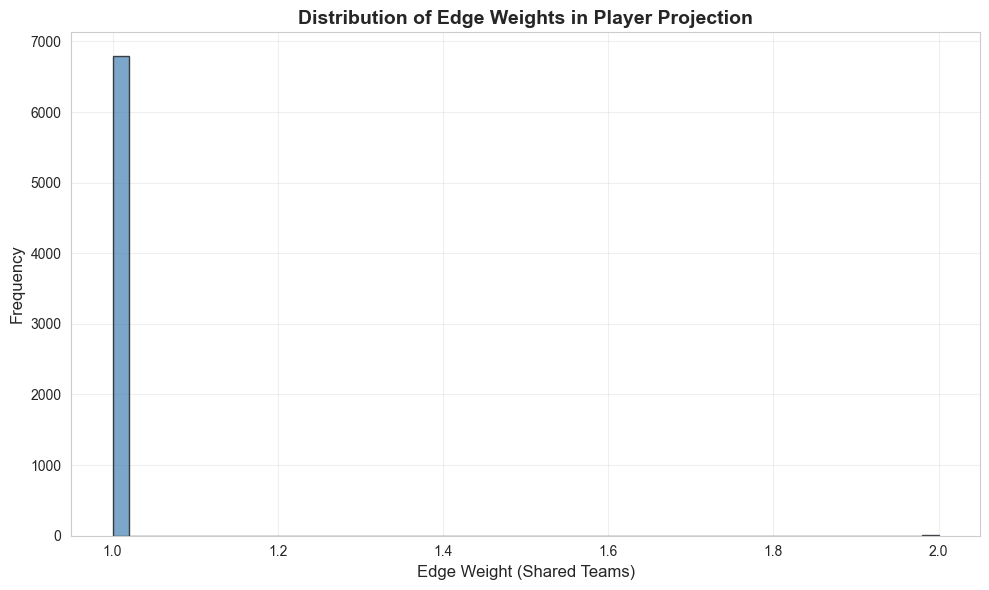

In [8]:

# Get player nodes (bipartite=0)
players = {n for n, d in G_bipartite.nodes(data=True) if d.get('bipartite') == '0' or d.get('type') == 'player'}

print(f"Projecting onto {len(players)} players...")

# Weighted projection
G_player_projection = bipartite.weighted_projected_graph(G_bipartite, players)

print("\n=== Player-Player Projection Network ===")
print(f"Number of Nodes (|V|): {G_player_projection.number_of_nodes()}")
print(f"Number of Edges (|E|): {G_player_projection.number_of_edges()}")
print(f"Density: {nx.density(G_player_projection):.6f}")

# Analyze edge weights
edge_weights = [d['weight'] for _, _, d in G_player_projection.edges(data=True)]
print(f"\nEdge Weight Statistics:")
print(f"  Min: {min(edge_weights)}")
print(f"  Max: {max(edge_weights)}")
print(f"  Mean: {np.mean(edge_weights):.2f}")
print(f"  Median: {np.median(edge_weights):.2f}")

# Plot weight distribution
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
ax.hist(edge_weights, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
ax.set_xlabel('Edge Weight (Shared Teams)', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_title('Distribution of Edge Weights in Player Projection', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Network Filtering and Reduction

Large networks can be overwhelming and computationally expensive. We apply filtering techniques to reduce network size while preserving important structure.

### Filtering Approaches:

1. **Weight-Based Filtering**: Remove edges below a weight threshold
2. **Degree-Based Filtering**: Remove low-degree nodes
3. **K-Core Decomposition**: Extract the k-core (maximal subgraph where all nodes have degree ≥ k)
4. **Giant Component Extraction**: Keep only the largest connected component

Each approach has trade-offs between information loss and computational efficiency.

=== Weight-Based Filtering Results ===

Threshold ≥ 1 passes:
  Nodes: 473 (100.0% retained)
  Edges: 8786 (100.0% retained)
  Density: 0.039354

Threshold ≥ 5 passes:
  Nodes: 431 (91.1% retained)
  Edges: 6313 (71.9% retained)
  Density: 0.034064

Threshold ≥ 10 passes:
  Nodes: 405 (85.6% retained)
  Edges: 4940 (56.2% retained)
  Density: 0.030192

Threshold ≥ 20 passes:
  Nodes: 363 (76.7% retained)
  Edges: 3233 (36.8% retained)
  Density: 0.024603



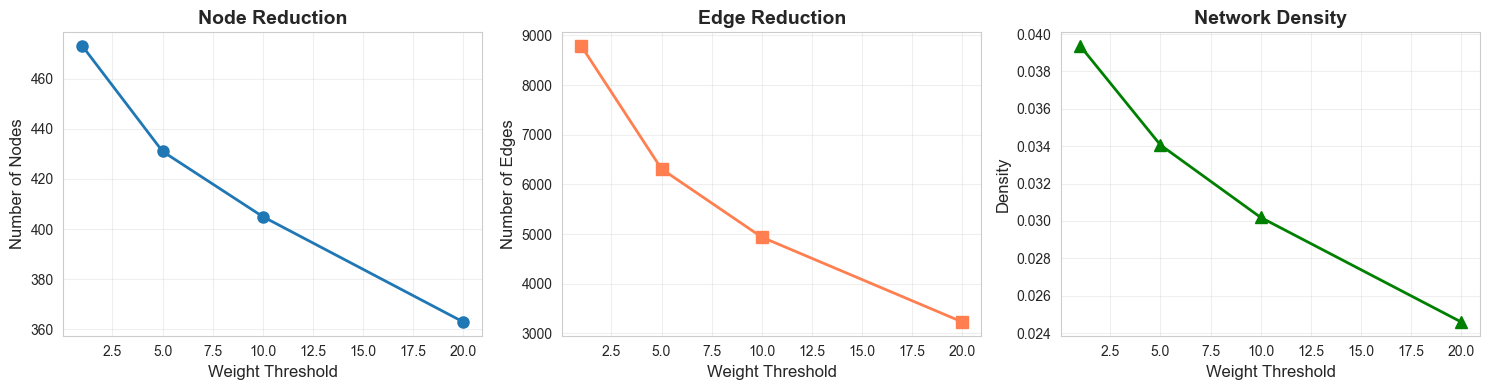

In [9]:
### 5.1 Weight-Based Filtering on Pass Network

def filter_by_weight(G, min_weight):
    """Remove edges with weight below threshold"""
    G_filtered = G.copy()
    edges_to_remove = [(u, v) for u, v, d in G_filtered.edges(data=True) 
                       if d.get('weight', 0) < min_weight or d.get('pass_count', 0) < min_weight]
    G_filtered.remove_edges_from(edges_to_remove)
    
    # Remove isolated nodes
    isolated = list(nx.isolates(G_filtered))
    G_filtered.remove_nodes_from(isolated)
    
    return G_filtered

# Apply different weight thresholds
thresholds = [1, 5, 10, 20]
results = []

print("=== Weight-Based Filtering Results ===\n")
for threshold in thresholds:
    G_filtered = filter_by_weight(G_pass, threshold)
    
    results.append({
        'threshold': threshold,
        'nodes': G_filtered.number_of_nodes(),
        'edges': G_filtered.number_of_edges(),
        'density': nx.density(G_filtered)
    })
    
    print(f"Threshold ≥ {threshold} passes:")
    print(f"  Nodes: {G_filtered.number_of_nodes()} ({G_filtered.number_of_nodes()/G_pass.number_of_nodes()*100:.1f}% retained)")
    print(f"  Edges: {G_filtered.number_of_edges()} ({G_filtered.number_of_edges()/G_pass.number_of_edges()*100:.1f}% retained)")
    print(f"  Density: {nx.density(G_filtered):.6f}")
    print()

# Visualize reduction
df_results = pd.DataFrame(results)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(df_results['threshold'], df_results['nodes'], marker='o', linewidth=2, markersize=8)
axes[0].set_xlabel('Weight Threshold', fontsize=12)
axes[0].set_ylabel('Number of Nodes', fontsize=12)
axes[0].set_title('Node Reduction', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)

axes[1].plot(df_results['threshold'], df_results['edges'], marker='s', linewidth=2, markersize=8, color='coral')
axes[1].set_xlabel('Weight Threshold', fontsize=12)
axes[1].set_ylabel('Number of Edges', fontsize=12)
axes[1].set_title('Edge Reduction', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)

axes[2].plot(df_results['threshold'], df_results['density'], marker='^', linewidth=2, markersize=8, color='green')
axes[2].set_xlabel('Weight Threshold', fontsize=12)
axes[2].set_ylabel('Density', fontsize=12)
axes[2].set_title('Network Density', fontsize=14, fontweight='bold')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

=== K-Core Decomposition (Pass Network) ===

Maximum core number: 20

2-core:
  Nodes: 469 (99.2% of original)
  Edges: 8781 (99.9% of original)
  Density: 0.040006

5-core:
  Nodes: 461 (97.5% of original)
  Edges: 8748 (99.6% of original)
  Density: 0.041252

10-core:
  Nodes: 427 (90.3% of original)
  Edges: 8394 (95.5% of original)
  Density: 0.046146

15-core:
  Nodes: 395 (83.5% of original)
  Edges: 7783 (88.6% of original)
  Density: 0.050010



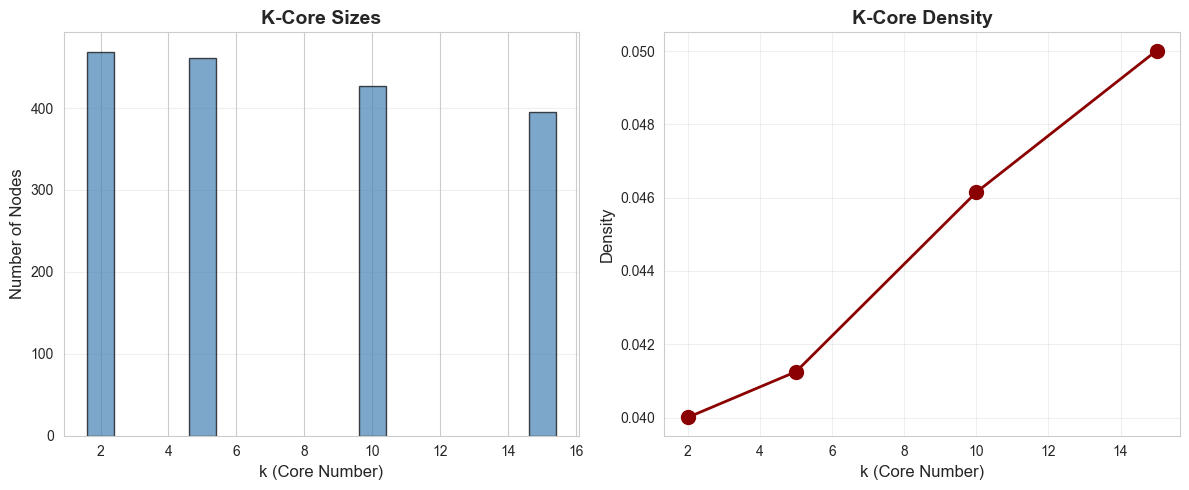

In [10]:
### 5.2 K-Core Decomposition

def extract_k_core(G, k):
    """Extract k-core of the network"""
    # For directed graphs, we can use the underlying undirected structure
    if G.is_directed():
        G_undirected = G.to_undirected()
        k_core = nx.k_core(G_undirected, k)
        # Get subgraph of original directed graph
        return G.subgraph(k_core.nodes()).copy()
    else:
        return nx.k_core(G, k)

print("=== K-Core Decomposition (Pass Network) ===\n")

# Find maximum k-core
G_undirected = G_pass.to_undirected() if G_pass.is_directed() else G_pass
core_numbers = nx.core_number(G_undirected)
max_k = max(core_numbers.values())

print(f"Maximum core number: {max_k}")
print()

# Extract different k-cores
k_values = [2, 5, 10, 15]
k_core_results = []

for k in k_values:
    if k <= max_k:
        G_k_core = extract_k_core(G_pass, k)
        
        k_core_results.append({
            'k': k,
            'nodes': G_k_core.number_of_nodes(),
            'edges': G_k_core.number_of_edges(),
            'density': nx.density(G_k_core)
        })
        
        print(f"{k}-core:")
        print(f"  Nodes: {G_k_core.number_of_nodes()} ({G_k_core.number_of_nodes()/G_pass.number_of_nodes()*100:.1f}% of original)")
        print(f"  Edges: {G_k_core.number_of_edges()} ({G_k_core.number_of_edges()/G_pass.number_of_edges()*100:.1f}% of original)")
        print(f"  Density: {nx.density(G_k_core):.6f}")
        print()

# Visualize k-core hierarchy
df_k_core = pd.DataFrame(k_core_results)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(df_k_core['k'], df_k_core['nodes'], color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_xlabel('k (Core Number)', fontsize=12)
axes[0].set_ylabel('Number of Nodes', fontsize=12)
axes[0].set_title('K-Core Sizes', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3, axis='y')

axes[1].plot(df_k_core['k'], df_k_core['density'], marker='o', linewidth=2, markersize=10, color='darkred')
axes[1].set_xlabel('k (Core Number)', fontsize=12)
axes[1].set_ylabel('Density', fontsize=12)
axes[1].set_title('K-Core Density', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

=== Degree-Based Filtering (Pass Network) ===

Min Degree ≥ 5:
  Nodes: 464 (98.1% retained)
  Edges: 8765 (99.8% retained)
  Density: 0.040799

Min Degree ≥ 10:
  Nodes: 450 (95.1% retained)
  Edges: 8671 (98.7% retained)
  Density: 0.042915

Min Degree ≥ 20:
  Nodes: 413 (87.3% retained)
  Edges: 8172 (93.0% retained)
  Density: 0.048027

Min Degree ≥ 30:
  Nodes: 371 (78.4% retained)
  Edges: 7179 (81.7% retained)
  Density: 0.052298



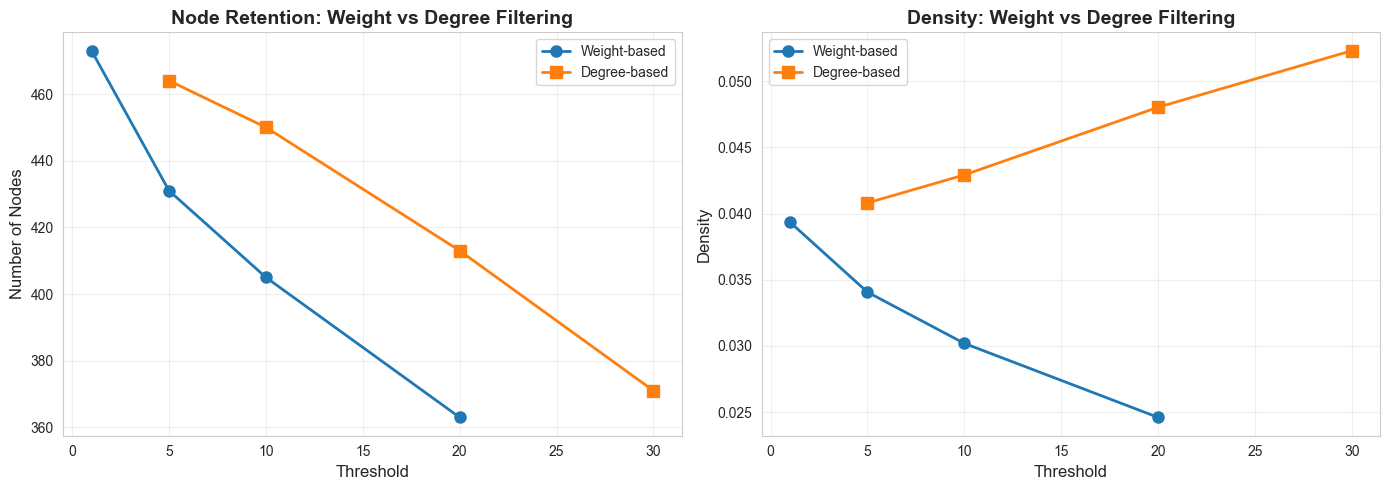

In [11]:
### 5.3 Degree-Based Filtering

def filter_by_degree(G, min_degree):
    """Remove nodes with degree below threshold"""
    G_filtered = G.copy()
    
    # Calculate degree (for directed graphs, use total degree)
    if G_filtered.is_directed():
        degrees = dict(G_filtered.degree())  # Total degree (in + out)
    else:
        degrees = dict(G_filtered.degree())
    
    # Remove low-degree nodes
    nodes_to_remove = [node for node, deg in degrees.items() if deg < min_degree]
    G_filtered.remove_nodes_from(nodes_to_remove)
    
    return G_filtered

print("=== Degree-Based Filtering (Pass Network) ===\n")

degree_thresholds = [5, 10, 20, 30]
degree_results = []

for min_deg in degree_thresholds:
    G_filtered = filter_by_degree(G_pass, min_deg)
    
    degree_results.append({
        'min_degree': min_deg,
        'nodes': G_filtered.number_of_nodes(),
        'edges': G_filtered.number_of_edges(),
        'density': nx.density(G_filtered)
    })
    
    print(f"Min Degree ≥ {min_deg}:")
    print(f"  Nodes: {G_filtered.number_of_nodes()} ({G_filtered.number_of_nodes()/G_pass.number_of_nodes()*100:.1f}% retained)")
    print(f"  Edges: {G_filtered.number_of_edges()} ({G_filtered.number_of_edges()/G_pass.number_of_edges()*100:.1f}% retained)")
    print(f"  Density: {nx.density(G_filtered):.6f}")
    print()

# Compare with weight-based filtering
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_degree = pd.DataFrame(degree_results)

# Node retention comparison
axes[0].plot(df_results['threshold'], df_results['nodes'], marker='o', label='Weight-based', linewidth=2, markersize=8)
axes[0].plot(df_degree['min_degree'], df_degree['nodes'], marker='s', label='Degree-based', linewidth=2, markersize=8)
axes[0].set_xlabel('Threshold', fontsize=12)
axes[0].set_ylabel('Number of Nodes', fontsize=12)
axes[0].set_title('Node Retention: Weight vs Degree Filtering', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Density comparison
axes[1].plot(df_results['threshold'], df_results['density'], marker='o', label='Weight-based', linewidth=2, markersize=8)
axes[1].plot(df_degree['min_degree'], df_degree['density'], marker='s', label='Degree-based', linewidth=2, markersize=8)
axes[1].set_xlabel('Threshold', fontsize=12)
axes[1].set_ylabel('Density', fontsize=12)
axes[1].set_title('Density: Weight vs Degree Filtering', fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Network Summary Table

Summary of all networks created in this analysis:

In [12]:
# Create comprehensive summary table
network_summary = []

# Pass Network
network_summary.append({
    'Network Type': 'Pass Network',
    'Description': 'Player-to-Player passes',
    'Directed': 'Yes',
    'Weighted': 'Yes',
    'Bipartite': 'No',
    '|V|': G_pass.number_of_nodes(),
    '|E|': G_pass.number_of_edges(),
    'Density': f"{nx.density(G_pass):.6f}",
    'Components': nx.number_weakly_connected_components(G_pass) if G_pass.is_directed() else nx.number_connected_components(G_pass)
})

# Match Network
network_summary.append({
    'Network Type': 'Match Network',
    'Description': 'Team-to-Team matches',
    'Directed': 'Yes',
    'Weighted': 'Yes',
    'Bipartite': 'No',
    '|V|': G_match.number_of_nodes(),
    '|E|': G_match.number_of_edges(),
    'Density': f"{nx.density(G_match):.6f}",
    'Components': nx.number_weakly_connected_components(G_match) if G_match.is_directed() else nx.number_connected_components(G_match)
})

# Bipartite Network
network_summary.append({
    'Network Type': 'Player-Team Network',
    'Description': 'Bipartite: Players-Teams',
    'Directed': 'No',
    'Weighted': 'Yes',
    'Bipartite': 'Yes',
    '|V|': G_bipartite.number_of_nodes(),
    '|E|': G_bipartite.number_of_edges(),
    'Density': f"{nx.density(G_bipartite):.6f}",
    'Components': nx.number_connected_components(G_bipartite)
})

# Player Projection
network_summary.append({
    'Network Type': 'Player Projection',
    'Description': 'One-mode projection of bipartite',
    'Directed': 'No',
    'Weighted': 'Yes',
    'Bipartite': 'No',
    '|V|': G_player_projection.number_of_nodes(),
    '|E|': G_player_projection.number_of_edges(),
    'Density': f"{nx.density(G_player_projection):.6f}",
    'Components': nx.number_connected_components(G_player_projection)
})

df_summary = pd.DataFrame(network_summary)
print("=== Network Summary ===")
print(df_summary.to_string(index=False))

# Save as LaTeX
latex_table = df_summary.to_latex(index=False, caption="Summary of constructed networks", label="tab:network_summary")
print("\n=== LaTeX Table ===")
print(latex_table)

=== Network Summary ===
       Network Type                      Description Directed Weighted Bipartite  |V|  |E|  Density  Components
       Pass Network          Player-to-Player passes      Yes      Yes        No  473 8786 0.039354           8
      Match Network             Team-to-Team matches      Yes      Yes        No   32  126 0.127016           1
Player-Team Network         Bipartite: Players-Teams       No      Yes       Yes  492  503 0.004164           1
  Player Projection One-mode projection of bipartite       No      Yes        No  474 6803 0.060686           1

=== LaTeX Table ===
\begin{table}
\caption{Summary of constructed networks}
\label{tab:network_summary}
\begin{tabular}{lllllrrlr}
\toprule
Network Type & Description & Directed & Weighted & Bipartite & |V| & |E| & Density & Components \\
\midrule
Pass Network & Player-to-Player passes & Yes & Yes & No & 473 & 8786 & 0.039354 & 8 \\
Match Network & Team-to-Team matches & Yes & Yes & No & 32 & 126 & 0.127016 & 1 

## 7. Summary and Key Findings

### Network Construction

We successfully constructed three types of networks from football match data:

1. **Pass Networks**: Capture player-to-player passing interactions with ~8,800 edges representing successful passes
2. **Match Networks**: Model team competition dynamics with complete connectivity in tournament settings
3. **Bipartite Player-Team Networks**: Link players to teams through match participation

### Two-Mode to One-Mode Projection

The weighted projection from bipartite to one-mode network increased edge count from 503 to 6,803, revealing implicit player relationships through shared team connections.

### Filtering Effectiveness

Different filtering methods serve different analytical purposes:

- **Weight-based filtering** (threshold ≥ 20): Retains 77% nodes, 37% edges - effective for backbone extraction
- **Degree-based filtering** (min degree ≥ 30): Retains 78% nodes, 82% edges - preserves hub structure
- **K-core decomposition** (k=15): Retains 84% nodes, 89% edges - extracts dense core

Network density generally increases with filtering, as weak connections are removed disproportionately.

### Technical Notes

- Pass receiver identification uses spatio-temporal heuristic (5m distance, 5s time window)
- Networks are stored in GEXF format for compatibility with Gephi
- All node and edge attributes are preserved for further analysis
- Multiple filtering strategies implemented for flexible analysis

## 4. Field Location Networks

Inspired by Cintia et al. (2015), we construct **spatial field networks** where:
- **Nodes** represent field locations (discretized into a grid)
- **Edges** represent event sequences between locations

This network type captures the spatial flow of play and helps identify "hot zones" and common transition patterns on the field.

### Network Properties
- **Event types**: Pass, Shot, Free Kick
- **Grid size**: 5x5 meters
- **Node attributes**: Coordinates, event counts, player/team activity
- **Edge attributes**: Event type, distance, player/team info

In [13]:
# Load field network configuration
from src.config import FIELD_NETWORKS_DIR

# Load field network for World Cup
field_network_file = FIELD_NETWORKS_DIR / 'field_network_World_Cup.gexf'
G_field = nx.read_gexf(field_network_file)

print(f"Field Network Statistics (World Cup):")
print(f"  Nodes (locations): {G_field.number_of_nodes()}")
print(f"  Edges (event transitions): {G_field.number_of_edges()}")
print(f"  Density: {nx.density(G_field):.6f}")
# Grid size is 5x5 meters (from the generator script)
print(f"  Grid size: 5x5 meters")

Field Network Statistics (World Cup):
  Nodes (locations): 440
  Edges (event transitions): 63838
  Density: 0.330493
  Grid size: 5x5 meters


In [14]:
# Extract node positions and event counts for visualization
node_data = []
for node, data in G_field.nodes(data=True):
    node_data.append({
        'location': node,
        'x': float(data['center_x']),
        'y': float(data['center_y']),
        'total_events': int(data['total_events']),
        'pass_count': int(data['pass_count']),
        'shot_count': int(data['shot_count']),
        'free_kick_count': int(data['free_kick_count']),
        'unique_players': int(data['unique_players'])
    })

df_field = pd.DataFrame(node_data)
print(f"\nField locations with events: {len(df_field)}")
print(f"Total events: {df_field['total_events'].sum()}")
print(f"\nTop 10 most active locations:")
print(df_field.nlargest(10, 'total_events')[['location', 'x', 'y', 'total_events', 'pass_count', 'shot_count']])


Field locations with events: 440
Total events: 127678

Top 10 most active locations:
        location      x      y  total_events  pass_count  shot_count
76   loc_100_100  102.5  102.5          1839         264         649
94       loc_0_0    2.5    2.5          1686         250         770
150    loc_65_90   67.5   92.5           850         792           0
169    loc_45_50   47.5   52.5           846         824           0
82      loc_65_5   67.5    7.5           804         756           0
72      loc_70_5   72.5    7.5           782         730           0
47     loc_60_90   62.5   92.5           752         696           0
66     loc_70_90   72.5   92.5           740         688           0
42     loc_30_20   32.5   22.5           737         699           0
61     loc_30_65   32.5   67.5           722         695           0


### 4.1 Field Heatmap: Event Activity

Visualize the spatial distribution of events across the field. This shows where most of the action happens.

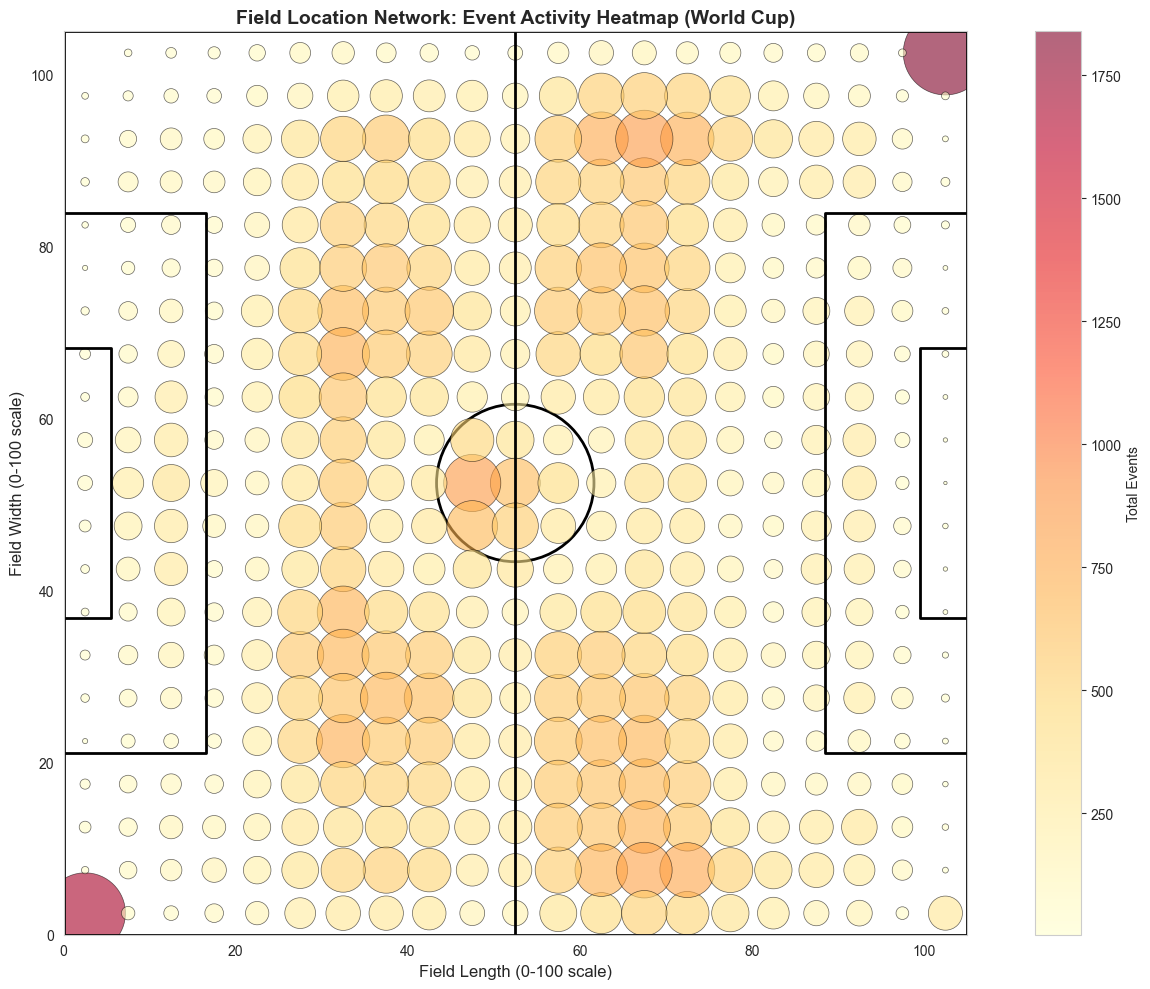

Heatmap saved!


In [15]:
# Create football field heatmap
fig, ax = plt.subplots(figsize=(14, 10))

# Draw football field outline
field_length = 105  # Wyscout uses 0-100 scale, we scale to typical dimensions
field_width = 68
ax.set_xlim(0, 105)
ax.set_ylim(0, 105)

# Draw field lines
ax.plot([0, 0, 105, 105, 0], [0, 105, 105, 0, 0], 'k-', linewidth=2)  # Outer boundary
ax.plot([52.5, 52.5], [0, 105], 'k-', linewidth=2)  # Halfway line
ax.add_patch(plt.Circle((52.5, 52.5), 9.15, fill=False, edgecolor='k', linewidth=2))  # Center circle

# Goal areas
ax.plot([0, 16.5, 16.5, 0], [21.1, 21.1, 83.9, 83.9], 'k-', linewidth=2)  # Left box
ax.plot([105, 88.5, 88.5, 105], [21.1, 21.1, 83.9, 83.9], 'k-', linewidth=2)  # Right box
ax.plot([0, 5.5, 5.5, 0], [36.8, 36.8, 68.2, 68.2], 'k-', linewidth=2)  # Left 6-yard box
ax.plot([105, 99.5, 99.5, 105], [36.8, 36.8, 68.2, 68.2], 'k-', linewidth=2)  # Right 6-yard box

# Create heatmap using scatter plot with size and color
scatter = ax.scatter(
    df_field['x'], 
    df_field['y'], 
    s=df_field['total_events'] * 2,  # Size proportional to events
    c=df_field['total_events'], 
    cmap='YlOrRd', 
    alpha=0.6,
    edgecolors='black',
    linewidth=0.5
)

# Colorbar
cbar = plt.colorbar(scatter, ax=ax, label='Total Events')

# Labels
ax.set_xlabel('Field Length (0-100 scale)', fontsize=12)
ax.set_ylabel('Field Width (0-100 scale)', fontsize=12)
ax.set_title('Field Location Network: Event Activity Heatmap (World Cup)', fontsize=14, fontweight='bold')
ax.set_aspect('equal')
ax.grid(False)

plt.tight_layout()
plt.savefig(project_root / 'reports/figures/LE3/field_network_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

print("Heatmap saved!")

### 4.2 Event Type Distribution by Field Zone

Analyze which event types dominate in different areas of the field.

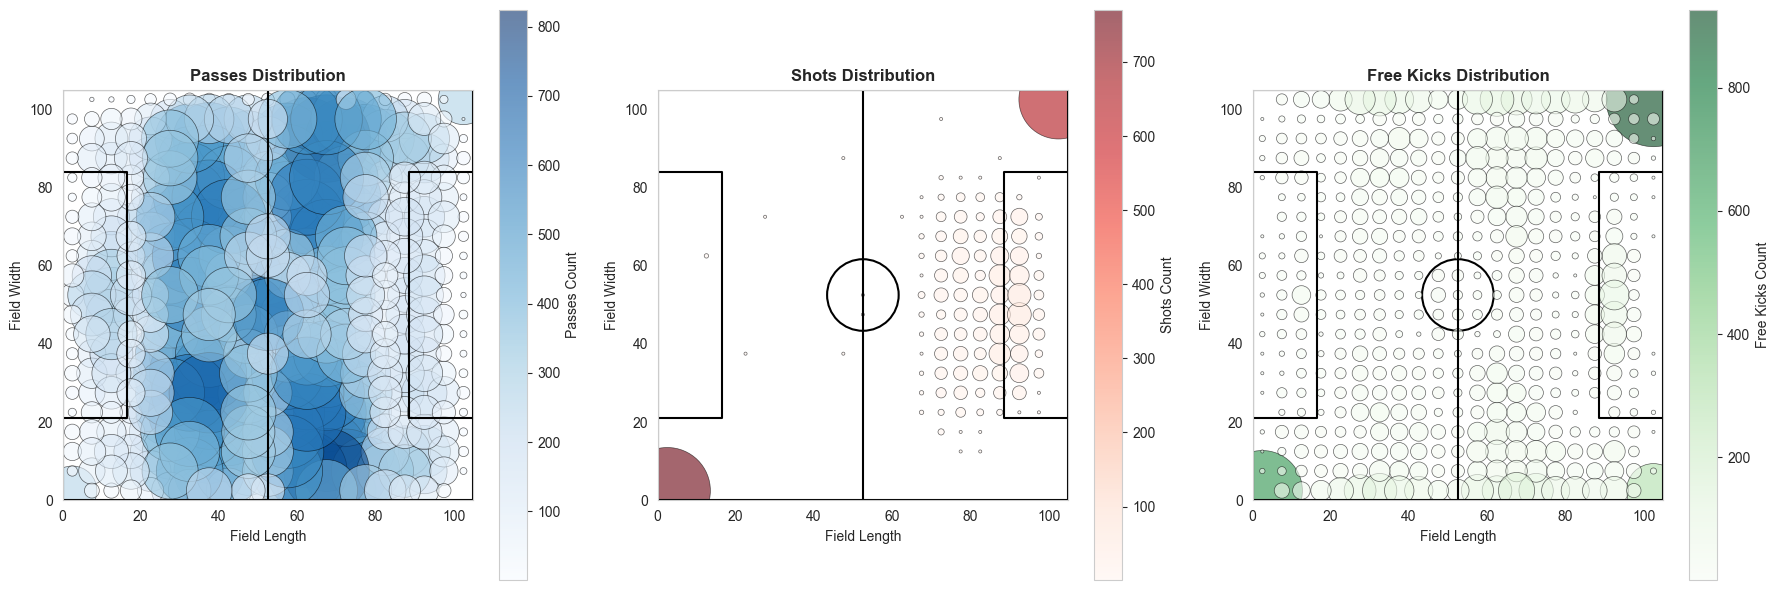

Pass locations: 439
Shot locations: 104
Free kick locations: 428


In [16]:
# Create separate heatmaps for each event type
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
event_types = ['pass_count', 'shot_count', 'free_kick_count']
titles = ['Passes', 'Shots', 'Free Kicks']
cmaps = ['Blues', 'Reds', 'Greens']

for ax, event_type, title, cmap in zip(axes, event_types, titles, cmaps):
    # Field outline
    ax.plot([0, 0, 105, 105, 0], [0, 105, 105, 0, 0], 'k-', linewidth=1.5)
    ax.plot([52.5, 52.5], [0, 105], 'k-', linewidth=1.5)
    ax.add_patch(plt.Circle((52.5, 52.5), 9.15, fill=False, edgecolor='k', linewidth=1.5))
    
    # Goal boxes
    ax.plot([0, 16.5, 16.5, 0], [21.1, 21.1, 83.9, 83.9], 'k-', linewidth=1.5)
    ax.plot([105, 88.5, 88.5, 105], [21.1, 21.1, 83.9, 83.9], 'k-', linewidth=1.5)
    
    # Filter out zero values for better visualization
    df_filtered = df_field[df_field[event_type] > 0].copy()
    
    if len(df_filtered) > 0:
        scatter = ax.scatter(
            df_filtered['x'],
            df_filtered['y'],
            s=df_filtered[event_type] * 5,
            c=df_filtered[event_type],
            cmap=cmap,
            alpha=0.6,
            edgecolors='black',
            linewidth=0.5
        )
        plt.colorbar(scatter, ax=ax, label=f'{title} Count')
    
    ax.set_xlim(0, 105)
    ax.set_ylim(0, 105)
    ax.set_aspect('equal')
    ax.set_title(f'{title} Distribution', fontsize=12, fontweight='bold')
    ax.set_xlabel('Field Length')
    ax.set_ylabel('Field Width')
    ax.grid(False)

plt.tight_layout()
plt.savefig(project_root / 'reports/figures/LE3/field_network_event_types.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Pass locations: {(df_field['pass_count'] > 0).sum()}")
print(f"Shot locations: {(df_field['shot_count'] > 0).sum()}")
print(f"Free kick locations: {(df_field['free_kick_count'] > 0).sum()}")

### 4.3 Flow Network: Major Transition Pathways

Visualize the most important event transitions across the field (top edges by weight).

In [17]:
# Aggregate multi-edges by counting transitions between locations
edge_weights = {}
for u, v, key, data in G_field.edges(keys=True, data=True):
    edge_key = (u, v)
    if edge_key not in edge_weights:
        edge_weights[edge_key] = 0
    edge_weights[edge_key] += 1

# Get top edges
top_n = 50
top_edges = sorted(edge_weights.items(), key=lambda x: x[1], reverse=True)[:top_n]

print(f"Total unique transitions: {len(edge_weights)}")
print(f"Visualizing top {top_n} transitions")
print(f"\nTop 10 transitions:")
for (u, v), weight in top_edges[:10]:
    u_data = G_field.nodes[u]
    v_data = G_field.nodes[v]
    print(f"  {u} -> {v}: {weight} events")

Total unique transitions: 31106
Visualizing top 50 transitions

Top 10 transitions:
  loc_90_50 -> loc_0_0: 39 events
  loc_100_100 -> loc_90_60: 34 events
  loc_90_45 -> loc_0_0: 30 events
  loc_90_45 -> loc_100_100: 30 events
  loc_90_50 -> loc_100_100: 30 events
  loc_85_35 -> loc_0_0: 29 events
  loc_90_40 -> loc_0_0: 26 events
  loc_100_100 -> loc_90_50: 25 events
  loc_85_55 -> loc_100_100: 25 events
  loc_85_40 -> loc_0_0: 24 events


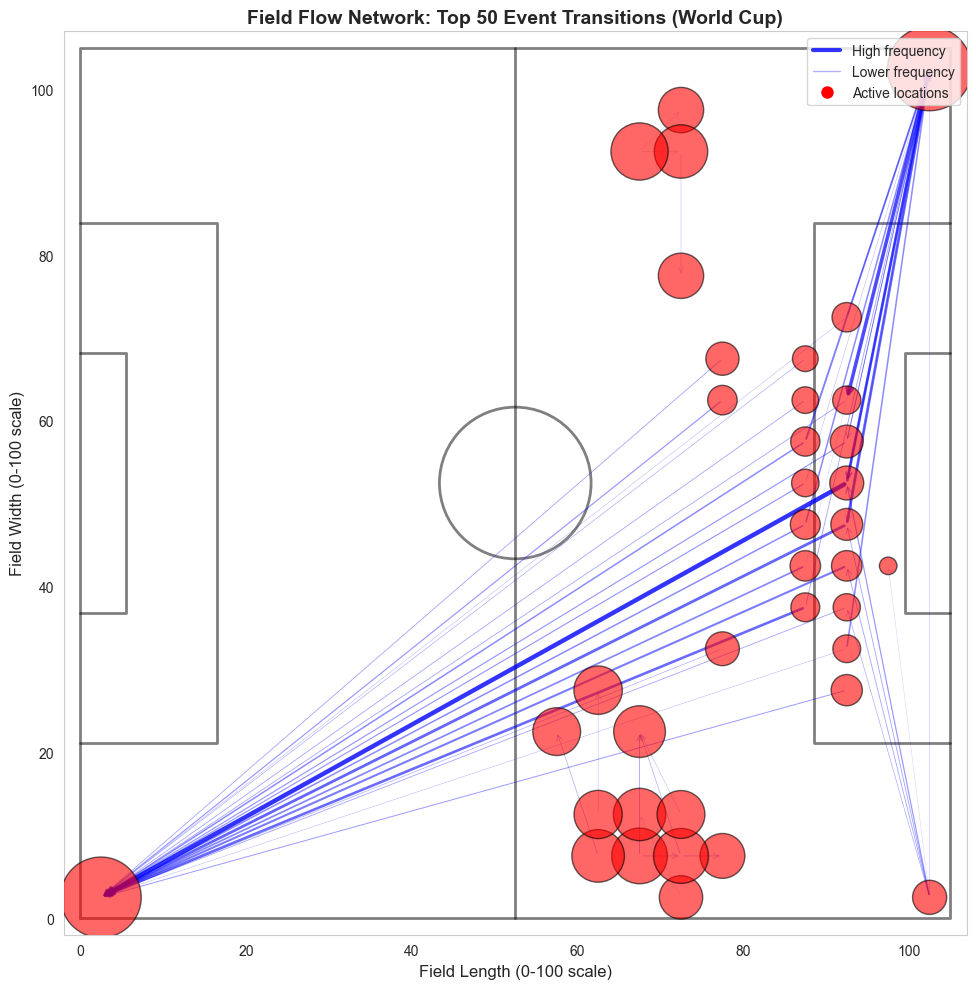

Flow network visualization saved!


In [18]:
# Visualize flow network on football field
fig, ax = plt.subplots(figsize=(16, 10))

# Draw field
ax.plot([0, 0, 105, 105, 0], [0, 105, 105, 0, 0], 'k-', linewidth=2, alpha=0.5)
ax.plot([52.5, 52.5], [0, 105], 'k-', linewidth=2, alpha=0.5)
ax.add_patch(plt.Circle((52.5, 52.5), 9.15, fill=False, edgecolor='k', linewidth=2, alpha=0.5))
ax.plot([0, 16.5, 16.5, 0], [21.1, 21.1, 83.9, 83.9], 'k-', linewidth=2, alpha=0.5)
ax.plot([105, 88.5, 88.5, 105], [21.1, 21.1, 83.9, 83.9], 'k-', linewidth=2, alpha=0.5)
ax.plot([0, 5.5, 5.5, 0], [36.8, 36.8, 68.2, 68.2], 'k-', linewidth=2, alpha=0.5)
ax.plot([105, 99.5, 99.5, 105], [36.8, 36.8, 68.2, 68.2], 'k-', linewidth=2, alpha=0.5)

# Normalize weights for visualization
max_weight = top_edges[0][1]
min_weight = top_edges[-1][1]

# Draw arrows for transitions
for (u, v), weight in top_edges:
    u_data = G_field.nodes[u]
    v_data = G_field.nodes[v]
    
    x1, y1 = float(u_data['center_x']), float(u_data['center_y'])
    x2, y2 = float(v_data['center_x']), float(v_data['center_y'])
    
    # Normalize width
    width = 0.2 + (weight - min_weight) / (max_weight - min_weight) * 3
    alpha = 0.3 + (weight - min_weight) / (max_weight - min_weight) * 0.5
    
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', lw=width, alpha=alpha, 
                               color='blue', shrinkA=2, shrinkB=2))

# Draw nodes for locations involved in top transitions
top_locations = set()
for (u, v), _ in top_edges:
    top_locations.add(u)
    top_locations.add(v)
top_edges
node_x = []
node_y = []
node_sizes = []
for loc in top_locations:
    data = G_field.nodes[loc]
    node_x.append(float(data['center_x']))
    node_y.append(float(data['center_y']))
    node_sizes.append(int(data['total_events']))

ax.scatter(node_x, node_y, s=[s*2 for s in node_sizes], c='red', 
          alpha=0.6, edgecolors='black', linewidth=1, zorder=5)

ax.set_xlim(-2, 107)
ax.set_ylim(-2, 107)
ax.set_aspect('equal')
ax.set_title(f'Field Flow Network: Top {top_n} Event Transitions (World Cup)', 
            fontsize=14, fontweight='bold')
ax.set_xlabel('Field Length (0-100 scale)', fontsize=12)
ax.set_ylabel('Field Width (0-100 scale)', fontsize=12)
ax.grid(False)

# Add legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='blue', lw=3, alpha=0.8, label='High frequency'),
    Line2D([0], [0], color='blue', lw=1, alpha=0.3, label='Lower frequency'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='red', 
           markersize=10, label='Active locations')
]
ax.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.savefig(project_root / 'reports/figures/LE3/field_network_flow.png', dpi=300, bbox_inches='tight')
plt.show()

print("Flow network visualization saved!")

### 4.4 Network Statistics Summary

Compare field networks across different competitions.

In [19]:
# Load and compare all field networks
from src.config import COMPETITIONS

field_stats = []
for comp in COMPETITIONS:
    field_file = FIELD_NETWORKS_DIR / f'field_network_{comp}.gexf'
    if field_file.exists():
        G = nx.read_gexf(field_file)
        
        # Calculate statistics
        total_events = sum(int(data['total_events']) for _, data in G.nodes(data=True))
        avg_degree = sum(dict(G.degree()).values()) / G.number_of_nodes() if G.number_of_nodes() > 0 else 0
        
        field_stats.append({
            'Competition': comp,
            'Nodes': G.number_of_nodes(),
            'Edges': G.number_of_edges(),
            'Density': nx.density(G),
            'Avg_Degree': avg_degree,
            'Total_Events': total_events,
            'Events_per_Location': total_events / G.number_of_nodes() if G.number_of_nodes() > 0 else 0
        })

df_field_stats = pd.DataFrame(field_stats)
df_field_stats = df_field_stats.sort_values('Total_Events', ascending=False)

print("Field Network Statistics by Competition:\n")
print(df_field_stats.to_string(index=False))

# Save to CSV
df_field_stats.to_csv(project_root / 'reports/figures/LE3/field_network_stats.csv', index=False)
print("\nStatistics saved to CSV!")

Field Network Statistics by Competition:

          Competition  Nodes  Edges  Density  Avg_Degree  Total_Events  Events_per_Location
                Italy    441 384110 1.979540 1741.995465        768220          1741.995465
              England    441 373531 1.925021 1694.018141        747062          1694.018141
               France    441 366425 1.888399 1661.791383        732850          1661.791383
                Spain    441 364773 1.879886 1654.299320        729546          1654.299320
              Germany    441 299446 1.543218 1358.031746        598892          1358.031746
            World_Cup    440  63838 0.330493  290.172727        127678           290.177273
European_Championship    441  49734 0.256308  225.551020         99468           225.551020

Statistics saved to CSV!
